In [1]:
# load dependencies
import numpy as np
import pandas as pd
import skgstat as skg
import xarray as xr
from sklearn.preprocessing import QuantileTransformer
from skgstat import models
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
import gstatsim as gs
import random
import os

In [2]:
# import data
ds = xr.open_dataset('Data/BedMachineAntarctica-v3.nc')

In [3]:
# set coordinates (in polar stereographic units)
xmin = -1673_250
xmax = -955_250
ymin = -1277_250
ymax = -505_250

x_slice = slice(xmin, xmax) if ds.x[0] < ds.x[-1] else slice(xmax, xmin)
y_slice = slice(ymin, ymax) if ds.y[0] < ds.y[-1] else slice(ymax, ymin)
mbl = ds.sel(x=x_slice, y=y_slice)
mbl

<xarray.Dataset> Size: 55MB
Dimensions:    (y: 1544, x: 1436)
Coordinates:
  * y          (y) int32 6kB -505500 -506000 -506500 ... -1276500 -1277000
  * x          (x) int32 6kB -1673000 -1672500 -1672000 ... -956000 -955500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 2MB ...
    firn       (y, x) float32 9MB ...
    surface    (y, x) float32 9MB ...
    thickness  (y, x) float32 9MB ...
    bed        (y, x) float32 9MB ...
    errbed     (y, x) float32 9MB ...
    source     (y, x) int8 2MB ...
    dataid     (y, x) int8 2MB ...
    geoid      (y, x) int16 4MB ...
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [4]:
# #initial Pots from Bedmachine3

# #Plot bed elevation
# fig, ax = plt.subplots(figsize=(5, 3))
# mbl["bed"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True, vmin = -1000, vmax = 3500)
# ax.set_title("Bed Elevation")
# ax.set_aspect("equal")
# plt.show()

# #Plot Mask
# fig, ax = plt.subplots(figsize=(5, 3))
# mbl["mask"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True,)
# ax.set_title("Mask")
# ax.set_aspect("equal")
# plt.show()

# #Plot Ice Thickness
# fig, ax = plt.subplots(figsize=(5, 3))
# mbl["thickness"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True)
# ax.set_title("Ice Thickness")
# ax.set_aspect("equal")
# plt.show()

(np.float64(-1673500.0),
 np.float64(-955500.0),
 np.float64(-1277500.0),
 np.float64(-505500.0))

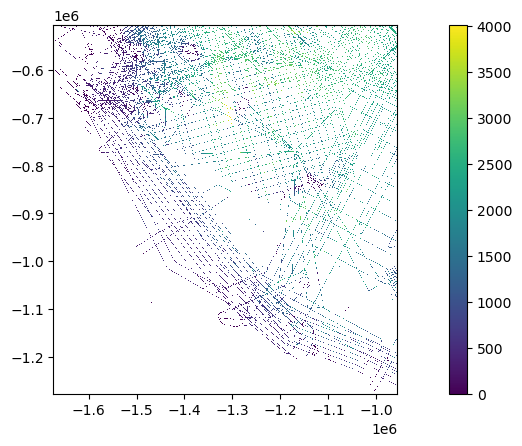

In [5]:
# #plotting radar data from bedmap3
# xmin_ant = -3333250
# xmax_ant = 3333250
# ymin_ant = -3333250
# ymax_ant = 3333250

# resolution = 500
# xx_ant, yy_ant = np.meshgrid(np.arange(xmin_ant, xmax_ant + resolution, resolution), 
#                      np.arange(ymin_ant, ymax_ant + resolution, resolution))

# xmin_ind = np.where(xx_ant == xmin)[1][0]
# xmax_ind = np.where(xx_ant == xmax)[1][0]
# ymin_ind = np.where(yy_ant == ymin)[0][0]
# ymax_ind = np.where(yy_ant == ymax)[0][0]

# radar_thickness = np.load('Data/bedmap3_raw_thick_compilation.npy')
# radar_thickness = np.flip(radar_thickness,axis=0)
# radar_thickness = radar_thickness[ymin_ind:ymax_ind,xmin_ind:xmax_ind]

# xx, yy = np.meshgrid(np.arange(xmin, xmax, resolution), 
#                      np.arange(ymin, ymax, resolution))

# plt.pcolormesh(xx,yy,radar_thickness)
# plt.colorbar()
# plt.axis('scaled')

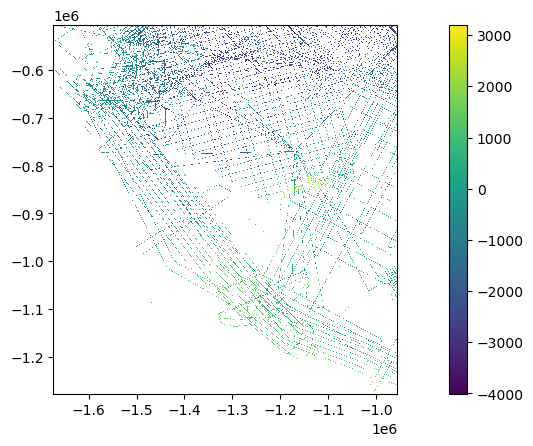

In [6]:
# #adding radar bed data to ds
# plt.pcolormesh(xx,yy,mbl['surface'].values.reshape(xx.shape) - radar_thickness)
# plt.colorbar()
# plt.axis('scaled')

# mbl['radar_bed'] = mbl['surface'] - np.flipud(radar_thickness)

In [ ]:
ocean = mbl['mask'] == 0
mbl['cond_bed'] = xr.where(ocean, mbl['bed'], mbl['radar_bed'])

In [8]:
#converts to df for calculations
df = mbl.to_dataframe().reset_index()
# grid data to 100 m resolution and remove coordinates with NaNs
res = 1000
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'cond_bed', res)
df_grid = df_grid[df_grid["Z"].isnull() == False]
df_grid = df_grid.rename(columns = {"Z": "Bed"})

# normal score transformation
data = df_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data)
df_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nbed']

maxlag = 50000             # maximum range distance
n_lags = 70                # num of bins

V1 = skg.Variogram(coords, values, bin_func='even', n_lags=n_lags, 
                   maxlag=maxlag, normalize=False)

# use exponential variogram model
V1.model = 'Exponential'
V1.parameters

[np.float64(49999.99999999981), np.float64(0.720875283283153), 0]

In [9]:
# gridding ice surface data
df_surface_grid, surface_grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'surface', res) # grid data
df_surface_grid = df_surface_grid.rename(columns = {"Z": "Surface"}) # rename column for consistency

# normal score transformation
data_surf = df_surface_grid['Surface'].values.reshape(-1,1)
nst_trans_surf = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data_surf)
df_surface_grid['Nsurf'] = nst_trans_surf.transform(data_surf) 

In [10]:
# find co-located secondary data 
df_colocated = gs.NearestNeighbor.find_colocated(df_grid, 'X', 'Y', 'Nbed', df_surface_grid, 'X', 'Y', 'Nsurf')

In [11]:
# compute correlation coefficient
rho12 = np.corrcoef(df_grid['Nbed'],df_colocated['colocated'])
corrcoef = rho12[0,1]
print('Correlation coefficient between bed and surface: ' + str(corrcoef))

Correlation coefficient between bed and surface: 0.028278854648328546


In [12]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

In [13]:
# set variogram parameters
azimuth = 0
nugget = V1.parameters[2]

# the major and minor ranges are the same in this example because it is isotropic
major_range = V1.parameters[0]
minor_range = V1.parameters[0]
sill = V1.parameters[1] 
vtype = 'matern'
smoothness = 1
vario = [azimuth, nugget, major_range, minor_range, sill, vtype, smoothness]

k = 100         # number of neighboring data points used to estimate a given point 
rad = 100000     # 50 km search radius

In [14]:
#creating settings for saving data before running loop
N_REALIZATIONS = 1
OUT_PATH       = "./MBL_first_realization.nc"
CHECKPOINT_DIR = "./realization_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [15]:
#creating grid geometry to save to later
cols = len(np.unique(Pred_grid_xy[:, 0]))
rows = len(np.unique(Pred_grid_xy[:, 1]))
x_vals = Pred_grid_xy[:, 0].reshape((rows, cols))[0, :].astype("float32")
y_vals = Pred_grid_xy[:, 1].reshape((rows, cols))[:, 0].astype("float32")

In [16]:
#split into 2 df, co sgs will be performed on upper, sgs on lower
mask = (df["surface"] >= 2250) & (df["bed"] >= 2000)
upper = df[mask]
lower = df[~mask]

In [ ]:
#creating for loop to actually run realizations 
realizations = []
for seed in range(N_REALIZATIONS):
    print(f"Realization {seed + 1}/{N_REALIZATIONS} (seed_id={seed})")
    #running cosim on everything
    #cokriging
    est_cokrige, var_cokrige = gs.Interpolation.cokrige_mm1(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', 
                                     df_surface_grid, 'X', 'Y', 'Nsurf', k, vario, rad, corrcoef)
    # reverse normal score transformation
    var_cokrige[var_cokrige < 0] = 0; # make sure variances are non-negative
    std_cokrige = np.sqrt(var_cokrige) # convert to standard deviation (this should be done before back transforming!!!)

    # reshape
    est = est_cokrige.reshape(-1,1)
    std = std_cokrige.reshape(-1,1)

    # back transformation
    cokrige_pred_trans = nst_trans.inverse_transform(est)
    cokrige_std_trans = nst_trans.inverse_transform(std)
    cokrige_std_trans = cokrige_std_trans - np.min(cokrige_std_trans)
    #cosim
    cosim = gs.Interpolation.cosim_mm1(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', 
                                     df_surface_grid, 'X', 'Y', 'Nsurf', k, vario, rad, corrcoef)
    # reverse normal score transformation
    sgs_cosim = cosim.reshape(-1,1)
    cosim_trans = nst_trans.inverse_transform(sgs_cosim)

    #simple kriging for sgs
    # est_SK is the estimate and var_SK is the variance
    est_SK, var_SK = gs.Interpolation.skrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad)
    # reverse normal score transformation

    var_SK[var_SK < 0] = 0      # make sure variances are non-negative
    std_SK = np.sqrt(var_SK)    # convert to standard deviation before back transforming

    # reshape
    est = est_SK.reshape(-1,1)
    std = std_SK.reshape(-1,1)

    # back transformation
    spred_trans = nst_trans.inverse_transform(est)
    sstd_trans = nst_trans.inverse_transform(std)
    sstd_trans = sstd_trans - np.min(sstd_trans)

    #ordinary kriging for sgs
    est_OK, var_OK = gs.Interpolation.okrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad) # estimation and variance

    # reverse normal score transformation
    var_OK[var_OK < 0] = 0; # make sure variances are non-negative
    std_OK = np.sqrt(var_OK) # convert to standard deviation (this should be done before back transforming!!!)

    # reshape
    est = est_OK.reshape(-1,1)
    std = std_OK.reshape(-1,1)

    # back transformation
    pred_trans = nst_trans.inverse_transform(est)
    std_trans = nst_trans.inverse_transform(std)
    std_trans = std_trans - np.min(std_trans)
    #sgs
    sim = gs.Interpolation.okrige_sgs(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad)
    # reverse normal score transformation
    sim1 = sim.reshape(-1,1)
    sim_trans = nst_trans.inverse_transform(sim1)

    #splitting data into upper and lower
    #upper
    df_to_combine_upper = pd.DataFrame({
        'x': Pred_grid_xy[:, 0],
        'y': Pred_grid_xy[:, 1],
        'sim': cosim_trans.ravel()
    })
    
    upper_subset = df_to_combine_upper.merge(upper[['x', 'y']].drop_duplicates(), on=['x', 'y'], how='inner')
    #lower
    df_to_combine_lower = pd.DataFrame({
        'x': Pred_grid_xy[:, 0],
        'y': Pred_grid_xy[:, 1],
        'sim': sim_trans.ravel()
    })
    lower_subset = df_to_combine_lower.merge(lower[['x', 'y']].drop_duplicates(), on=['x', 'y'], how='inner')
    #pred grid to map onto
    Pred_df = pd.DataFrame(Pred_grid_xy)
    Pred_df = Pred_df.rename(columns={0:"x", 1:"y"})
    #combining the upper and lower
    combined = pd.concat([lower_subset, upper_subset], ignore_index=True)
    combined = pd.merge(Pred_df, combined, on = ["x", "y"], how = "inner")
    combined_to_map = combined['sim'].to_numpy()

    da = xr.DataArray(
        combined_to_map.reshape((rows, cols)).astype("float32"),
        dims=("y", "x"),
        coords={"y": y_vals, "x": x_vals},
        name="realizations",
    ).expand_dims(seed_id=[seed])
    realizations.append(da)
    # checkpoint so a crash doesn't lose finished realizations
    da.to_netcdf(f"{CHECKPOINT_DIR}/realization_{seed:03d}.nc")

# ── Combine and write one NetCDF, same layout as smooth_test_area_3_real.nc ─
all_real = xr.concat(realizations, dim="seed_id").astype("float32")
all_real["seed_id"] = all_real["seed_id"].astype("int64")
all_real["x"].attrs["units"] = "metres"
all_real["y"].attrs["units"] = "metres"
all_real.attrs["long_name"] = "bed elevation ensemble"
all_real.attrs["units"] = "m"

out = all_real.to_dataset()
out.attrs["Conventions"] = "CF-1.8"
out.attrs["source"] = "Simulation_MBL.ipynb: co-SGS (upper) + SGS (lower), BedMachine/Bedmap3"

out.to_netcdf(
    OUT_PATH,
    format="NETCDF4",
    encoding={
        "realizations": dict(zlib=True, complevel=4, dtype="float32", _FillValue=np.nan,
                             chunksizes=(1, min(256, rows), min(256, cols))),
        "x": dict(_FillValue=None),
        "y": dict(_FillValue=None),
    },
)
print(f"Written: {OUT_PATH}  ({rows} x {cols}, {N_REALIZATIONS} realizations)")